In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D8/'

In [2]:
df_flat = pd.read_csv(main_dir + 'faiss_flat.csv')
df_flat['index'] = 'flat'
df_hnsw = pd.read_csv(main_dir + 'faiss_hnsw.csv')
df_hnsw['index'] = 'hnsw'
df_lsh = pd.read_csv(main_dir + 'faiss_lsh.csv')
df_lsh['index'] = 'lsh'

In [3]:
result = pd.DataFrame()
dfs = [df_flat, df_hnsw, df_lsh]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,22068,1,3.23,83.47,6.21,712,21356,23628,141,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,44136,2,1.74,90.04,3.41,768,43368,23684,85,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,66204,3,1.18,91.32,2.32,779,65425,23695,74,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,88272,4,0.89,92.26,1.77,787,87485,23703,66,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,110340,5,0.72,93.08,1.43,794,109546,23710,59,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,132408,6,0.51,79.72,1.02,680,131728,23596,173,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,154476,7,0.44,80.07,0.88,683,153793,23599,170,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,176544,8,0.39,80.30,0.77,685,175859,23601,168,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,198612,9,0.35,80.54,0.69,687,197925,23603,166,lsh,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    960
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    960
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    960
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    960
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    960
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
17    30
18    30
19    30
20    30
21    30
22    30
23    30
24    30
25    30
26    30
27    30
28    30
29    30
30    30
31    30
32    30
Name: count, dtype: int64

In [10]:
valid_rows = result[result['Recall %']>=80]
valid_rows

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,22068,1,3.23,83.47,6.21,712,21356,23628,141,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,44136,2,1.74,90.04,3.41,768,43368,23684,85,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,66204,3,1.18,91.32,2.32,779,65425,23695,74,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,88272,4,0.89,92.26,1.77,787,87485,23703,66,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,110340,5,0.72,93.08,1.43,794,109546,23710,59,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
949,FAISS LSH Blocking,220680,10,0.32,82.18,0.63,701,219979,23617,152,lsh,[title],1024,0,31,salted_qgrams,,4
956,FAISS LSH Blocking,154476,7,0.44,80.07,0.88,683,153793,23599,170,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,176544,8,0.39,80.30,0.77,685,175859,23601,168,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,198612,9,0.35,80.54,0.69,687,197925,23603,166,lsh,[title],1024,0,32,salted_qgrams,,4


In [11]:
valid_rows['index'].value_counts()

index
lsh     300
flat    299
hnsw    163
Name: count, dtype: int64

In [12]:
max_f1 = valid_rows.loc[valid_rows.groupby(['num_hashes','index'])['F1 %'].idxmax()]
max_f1

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,22068,1,3.23,83.47,6.21,712,21356,23628,141,flat,[title],1024,0,1,salted_qgrams,,4
640,FAISS LSH Blocking,22068,1,3.25,84.06,6.26,717,21351,23633,136,lsh,[title],1024,0,1,salted_qgrams,,4
10,FAISS FLAT Blocking,22068,1,3.22,83.24,6.20,710,21358,23626,143,flat,[title],1024,0,2,salted_qgrams,,4
650,FAISS LSH Blocking,22068,1,3.22,83.24,6.20,710,21358,23626,143,lsh,[title],1024,0,2,salted_qgrams,,4
20,FAISS FLAT Blocking,22068,1,3.25,84.17,6.26,718,21350,23634,135,flat,[title],1024,0,3,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
933,FAISS LSH Blocking,88272,4,0.78,81.01,1.55,691,87581,23607,162,lsh,[title],1024,0,30,salted_qgrams,,4
304,FAISS FLAT Blocking,110340,5,0.62,80.19,1.23,684,109656,23600,169,flat,[title],1024,0,31,salted_qgrams,,4
944,FAISS LSH Blocking,110340,5,0.62,80.19,1.23,684,109656,23600,169,lsh,[title],1024,0,31,salted_qgrams,,4
316,FAISS FLAT Blocking,154476,7,0.44,80.07,0.88,683,153793,23599,170,flat,[title],1024,0,32,salted_qgrams,,4


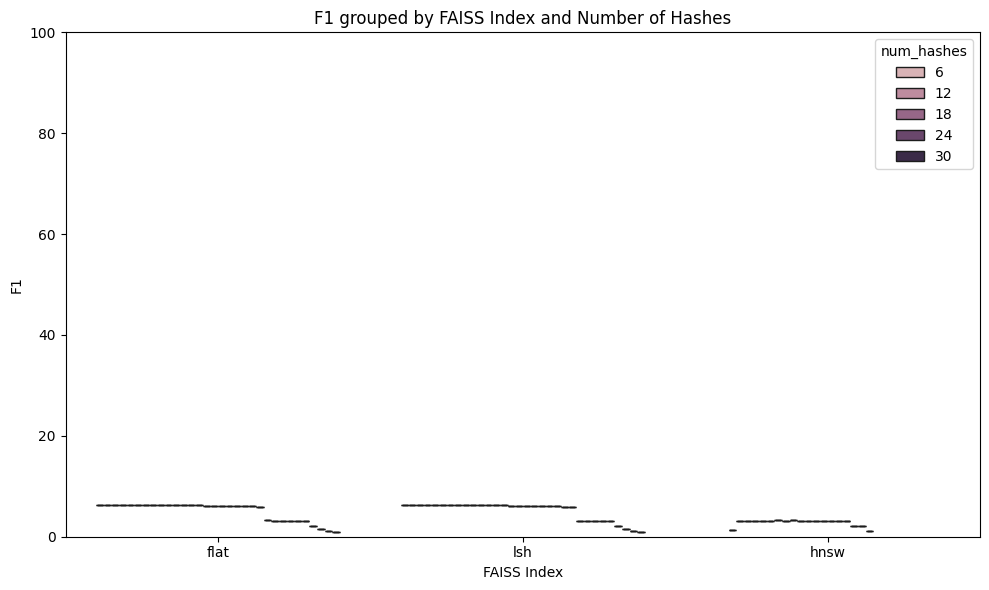

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="index",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by FAISS Index and Number of Hashes")
plt.xlabel("FAISS Index")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [14]:
metrics_df = max_f1.melt(
    id_vars=["index", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,index,num_hashes,Metric,Score
0,flat,1,Precision %,3.23
1,lsh,1,Precision %,3.25
2,flat,2,Precision %,3.22
3,lsh,2,Precision %,3.22
4,flat,3,Precision %,3.25
...,...,...,...,...
244,lsh,30,F1 %,1.55
245,flat,31,F1 %,1.23
246,lsh,31,F1 %,1.23
247,flat,32,F1 %,0.88


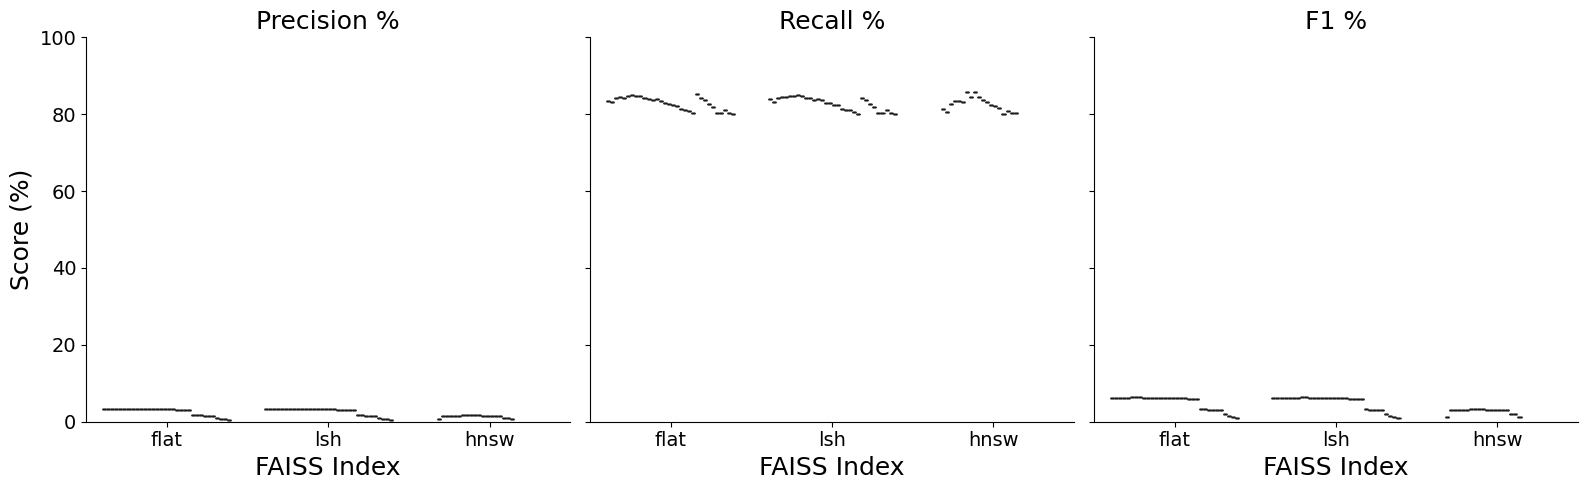

In [15]:
g = sns.catplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("FAISS Index", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

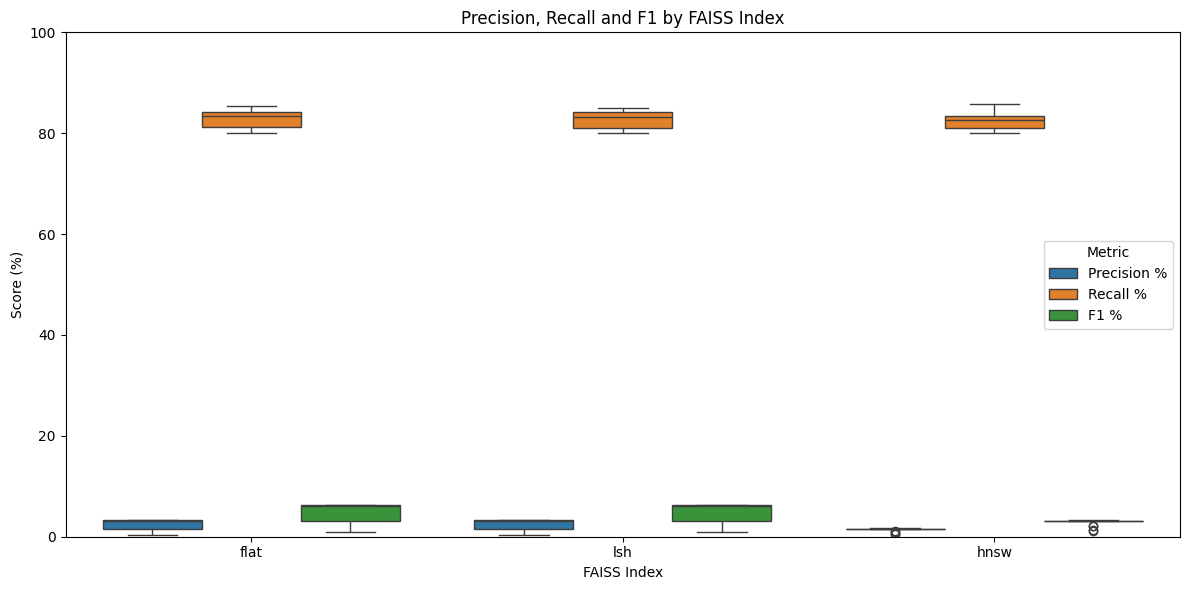

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by FAISS Index")
plt.xlabel("FAISS Index")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()